In [72]:
from crafts_stack.measure import Measurement, plt
from mytools.plot import save_plot

In [116]:
crafts_title_list = ['15', '30']

f_mean_list = [
    4.42,
    7.49,
]

f_std_list = [
    0.56,
    0.35,
]

bg_mean_list = [
    23.56,
    6.64,
]

bg_std_list = [
    0.72,
    0.48,
]

m_crafts_airpls_f = Measurement(2.23, 0.46)
m_crafts_airpls_bg = Measurement(0.57, 0.58)

In [117]:
m_f = Measurement(f_mean_list, f_std_list)
m_bg = Measurement(bg_mean_list, bg_std_list)

In [134]:
m_f.save('crafts_pca_f_15_30.npz')
m_bg.save('crafts_pca_bg_15_30.npz')
m_crafts_airpls_f.save('crafts_airpls_f.npz')
m_crafts_airpls_bg.save('crafts_airpls_bg.npz')

Measurement data saved to crafts_pca_f_15_30.npz
Measurement data saved to crafts_pca_bg_15_30.npz
Measurement data saved to crafts_airpls_f.npz
Measurement data saved to crafts_airpls_bg.npz


Single measurement replicated to match x_plot size: 2
Single measurement replicated to match x_plot size: 2


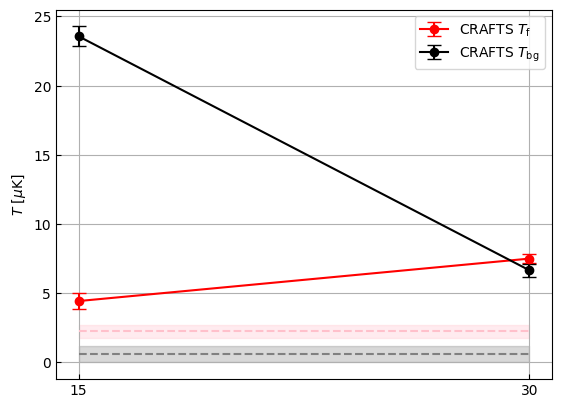

In [123]:
fig = plt.figure()
ax = fig.gca()
m_f.plot(ax=ax, label=r'CRAFTS $T_{\rm f}$', c='r')
m_bg.plot(ax=ax, label=r'CRAFTS $T_{\rm bg}$', c='k')
ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_xticks(range(2), crafts_title_list)
m_crafts_airpls_f.fill_plot(ax=ax, x=range(2), color='pink')
m_crafts_airpls_bg.fill_plot(ax=ax, x=range(2), color='gray')

In [28]:
tng_title_list = [ f'{i}' for i in range(0, 50, 5)]
print(tng_title_list)

tng_f_mean_list = [
    6.75,
    3.23,
    3.29,
    3.28,
    0.88,

    0.78,
    0.70,
    0.46,
    0.37,
    0.22
]

tng_f_std_list = [
    0.11,
    0.07,
    0.07,
    0.08,
    0.04,

    0.04,
    0.03,
    0.02,
    0.04,
    0.03
]

tng_bg_mean_list = [
    -2.21,
    -1.35,
    -1.73,
    -1.95,
    -0.49,

    -0.51,
    -0.42,
    -0.55,
    -0.72,
    -0.50
]

tng_bg_std_list = [
    0.10,
    0.05,
    0.04,
    0.05,
    0.04,

    0.02,
    0.03,
    0.02,
    0.03,
    0.03
]

['0', '5', '10', '15', '20', '25', '30', '35', '40', '45']


In [135]:
m_tng_f = Measurement(tng_f_mean_list, tng_f_std_list)
m_tng_bg = Measurement(tng_bg_mean_list, tng_bg_std_list)

transfer_f = m_tng_f[0]/ m_tng_f 
transfer_bg = m_tng_bg[0]/ m_tng_bg

In [136]:
m_tng_f.save('mock_crafts_pca_f.npz')
m_tng_bg.save('mock_crafts_pca_bg.npz')

Measurement data saved to mock_crafts_pca_f.npz
Measurement data saved to mock_crafts_pca_bg.npz


Plot saved to img_tng_pcaloss_signal_correction_factor.png


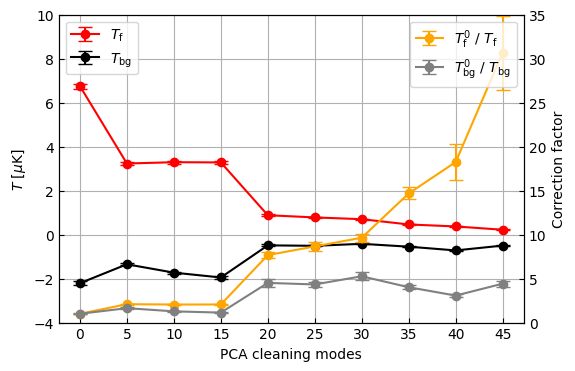

In [99]:
fig = plt.figure(figsize=(6,4))
ax = fig.gca()
m_tng_f.plot(ax=ax, label=r'$T_{\rm f}$', c='r')
m_tng_bg.plot(ax=ax, label=r'$T_{\rm bg}$', c='k')
ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_xticks(range(10), tng_title_list);
ax.set_ylim(-4, 10)
ax.legend(loc='upper left')

ax2 = ax.twinx()
transfer_f.plot(ax=ax2, label=r'$T_{\rm f}^0 \ /\ T_{\rm f}$', c='orange', grid=False)
transfer_bg.plot(ax=ax2, label=r'$T_{\rm bg}^0\ /\ T_{\rm bg}$', c='gray', grid=False)
ax2.set_ylabel('Correction factor')
ax2.set_ylim(0, 35)
ax2.legend(loc='upper right')

ax.set_xlabel('PCA cleaning modes')

fname = 'img_tng_pcaloss_signal_correction_factor.png'
save_plot(fig, fname)

In [ ]:
f_corrected = [m_f[0] * transfer_f[3], m_f[1] * transfer_f[6]]
bg_corrected = [m_bg[0] * transfer_bg[3], m_bg[1] * transfer_bg[6]]

In [127]:
f_corrected, bg_corrected

([9.0960 +/- 1.1829, 72.2250 +/- 4.7283],
 [26.7013 +/- 1.6107, 34.9390 +/- 3.8868])

In [112]:
m_f_corrected = Measurement([f.value for f in f_corrected], [f.error for f in f_corrected])
m_bg_corrected = Measurement([f.value for f in bg_corrected], [f.error for f in bg_corrected])

In [132]:
m_f_corrected.save('crafts_pca_corrected_f_15_30.npz')
m_bg_corrected.save('crafts_pca_corrected_bg_15_30.npz')

Measurement data saved to crafts_pca_corrected_f_15_30.npz
Measurement data saved to crafts_pca_corrected_bg_15_30.npz


Single measurement replicated to match x_plot size: 2
Single measurement replicated to match x_plot size: 2


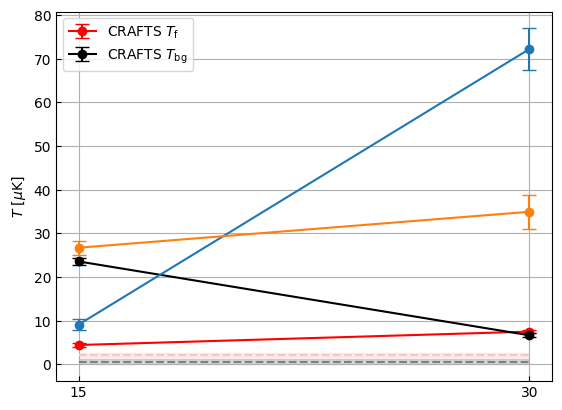

In [124]:
fig = plt.figure()
ax = fig.gca()
m_f.plot(ax=ax, label=r'CRAFTS $T_{\rm f}$', c='r')
m_bg.plot(ax=ax, label=r'CRAFTS $T_{\rm bg}$', c='k')
ax.set_ylabel(r'$T\ [\mu$K]')
ax.set_xticks(range(2), crafts_title_list)
m_crafts_airpls_f.fill_plot(ax=ax, x=range(2), color='pink')
m_crafts_airpls_bg.fill_plot(ax=ax, x=range(2), color='gray')

m_f_corrected.plot(ax=ax)
m_bg_corrected.plot(ax=ax)

In [128]:
m_f.get_snr(m_bg)

Values (size=2): [ 6.13888889 15.60416667]
Errors (size=2): [0.77777778 0.72916667]

In [125]:
m_f_corrected.get_snr(m_bg_corrected)

Values (size=2): [ 5.64725011 18.58232148]
Errors (size=2): [0.73441485 1.21652497]

In [126]:
m_crafts_airpls_f.get_snr(m_crafts_airpls_bg)

3.8448 +/- 0.7931